# TP2 — Complexité et généralisation

**Master 2 MIAGE — Introduction au Machine Learning**

Dans le TP1, nous avons construit un premier modèle capable de prédire le délai réel de livraison d'une commande.

Nous allons maintenant nous poser une autre question :

> **Comment améliorer les performances d'un modèle ?**

Nous conservons la même cible, `delivery_time_days`, et la même séparation entre entraînement, validation et test.

### Objectifs

À la fin du TP, vous devrez être capable de :

- faire varier la complexité d'un modèle ;
- comparer ses performances sur entraînement et validation ;
- identifier expérimentalement sous-apprentissage et sur-apprentissage ;
- comprendre l'intérêt de la régularisation ;
- étudier l'effet de Ridge et Lasso.

## 1. Reprendre notre problème de régression

Nous cherchons toujours à prédire le **délai réel de livraison** d'une commande Olist.

La variable cible $Y$ correspond à `delivery_time_days`.

Dans ce TP, nous travaillons volontairement avec un petit nombre de variables numériques afin de contrôler facilement la complexité du modèle.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "ndiayemairame/miage-machine-learning/"
    "main/data/orders_ml.csv"
)

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders_ml = pd.read_csv(DATA_URL, parse_dates=date_columns)

print("Dimensions :", orders_ml.shape)
orders_ml.head()

Dimensions : (96470, 33)


,order_id,customer_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_day_of_week,purchase_hour,...,max_product_volume_cm3,n_categories,freight_ratio,main_product_category,seller_customer_distance_mean,seller_customer_distance_max,same_state_share,payment_type_main,payment_installments_max,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,10,0,10,...,1976.0,1,0.290764,housewares,18.681737,18.681737,1.0,voucher,1.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,7,1,20,...,4693.0,1,0.191744,perfumery,861.036556,861.036556,0.0,boleto,1.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,8,2,8,...,9576.0,1,0.120200,auto,514.547851,514.547851,0.0,credit_card,3.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,11,5,19,...,6000.0,1,0.604444,pet_shop,1821.805173,1821.805173,0.0,credit_card,1.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,2,1,21,...,11475.0,1,0.438191,stationery,29.593135,29.593135,1.0,credit_card,1.0,5.0


## 2. Retrouver le même découpage que dans le TP1

Nous utilisons le même `random_state` et les mêmes proportions que dans le TP1 afin de conserver un protocole comparable.

In [2]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(
    orders_ml,
    test_size=0.30,
    random_state=42
)

validation, test = train_test_split(
    temp,
    test_size=0.50,
    random_state=42
)

print("Train      :", train.shape)
print("Validation :", validation.shape)
print("Test       :", test.shape)

Train      : (67529, 33)
Validation : (14470, 33)
Test       : (14471, 33)


## 3. Une première manière d'augmenter la complexité

Une régression linéaire classique construit une relation linéaire entre les variables explicatives et la prédiction.

Nous pouvons cependant enrichir les variables fournies au modèle. À partir de deux variables `x1` et `x2`, nous pouvons par exemple ajouter leurs carrés ou leur produit.

Le modèle reste une régression linéaire par rapport à ses coefficients, mais il dispose désormais d'une représentation plus riche des données.

Dans `scikit-learn`, `PolynomialFeatures` permet de réaliser automatiquement cette transformation.

Pour rendre l'expérience lisible et limiter le nombre de variables générées, nous utiliserons quatre variables numériques :

- `promised_delivery_days`
- `total_freight`
- `seller_customer_distance_mean`
- `mean_product_weight_g`

Pour cette expérience, nous retirons les commandes pour lesquelles l'une de ces informations est manquante.

In [3]:
features = [
    "promised_delivery_days",
    "total_freight",
    "seller_customer_distance_mean",
    "mean_product_weight_g",
]

target = "delivery_time_days"

train_poly = train.dropna(subset=features).copy()
validation_poly = validation.dropna(subset=features).copy()

X_train = train_poly[features]
y_train = train_poly[target]

X_val = validation_poly[features]
y_val = validation_poly[target]

print("Train exploitable      :", X_train.shape)
print("Validation exploitable :", X_val.shape)

Train exploitable      : (67174, 4)
Validation exploitable : (14392, 4)


### Une nouvelle transformation

Observons concrètement ce que produit un polynôme de degré 2 sur nos quatre variables.

In [4]:
from sklearn.preprocessing import PolynomialFeatures

poly_demo = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_demo = poly_demo.fit_transform(X_train)

print("Nombre de variables avant :", X_train.shape[1])
print("Nombre de variables après :", X_demo.shape[1])

poly_demo.get_feature_names_out(features)

Nombre de variables avant : 4
Nombre de variables après : 14


array(['promised_delivery_days', 'total_freight',
       'seller_customer_distance_mean', 'mean_product_weight_g',
       'promised_delivery_days^2', 'promised_delivery_days total_freight',
       'promised_delivery_days seller_customer_distance_mean',
       'promised_delivery_days mean_product_weight_g', 'total_freight^2',
       'total_freight seller_customer_distance_mean',
       'total_freight mean_product_weight_g',
       'seller_customer_distance_mean^2',
       'seller_customer_distance_mean mean_product_weight_g',
       'mean_product_weight_g^2'], dtype=object)

### Analyse

**Q4.** Combien de variables avions-nous avant la transformation ? Combien en avons-nous après ?

**Q5.** Concrètement, qu'a fait la transformation ?

**Q6.** Pourquoi peut-on dire que le modèle devient plus flexible alors que l'algorithme utilisé ensuite sera toujours `LinearRegression` ?

### ✍️ Votre réponse

**Q4.** Nous avions 4 variables. Nous en avons 14 après la transformation.

**Q5.** Elle conserve les 4 variables d'origine et ajoute leurs 4 carrés et leurs 6 produits deux à deux.

**Q6.** Le modèle reste linéaire par rapport à ses coefficients, donc `LinearRegression` s'applique sans changement. En revanche, la prédiction devient une fonction quadratique des variables d'origine. Le modèle peut ainsi capter des courbures et des interactions inaccessibles au degré 1.

## 4. Mesurer la performance sur train et validation

Cette fois, nous voulons comprendre ce qui se passe lorsque la complexité augmente. Nous allons donc observer simultanément l'erreur sur les données d'entraînement et l'erreur sur des données non utilisées pour apprendre les coefficients.

Nous utiliserons la RMSE pour suivre cette évolution.

In [5]:
from sklearn.metrics import mean_squared_error

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## 5. Modèle de degré 1

Avec `degree=1`, `PolynomialFeatures` ne crée pas de carré ni d'interaction : nous retrouvons essentiellement nos variables d'origine.

Le code du premier modèle est fourni afin de fixer le protocole que nous réutiliserons ensuite.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

degree_1_model = Pipeline([
    ("poly", PolynomialFeatures(degree=1, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

degree_1_model.fit(X_train, y_train)

pred_train_d1 = degree_1_model.predict(X_train)
pred_val_d1 = degree_1_model.predict(X_val)

rmse_train_d1 = rmse(y_train, pred_train_d1)
rmse_val_d1 = rmse(y_val, pred_val_d1)

pd.DataFrame({
    "RMSE train": [rmse_train_d1],
    "RMSE validation": [rmse_val_d1]
}, index=["Degré 1"])

,RMSE train,RMSE validation
Degré 1,8.57089,8.326118


### Première observation

**Q7.** Comparez la RMSE d'entraînement et la RMSE de validation.

**Q8.** Pourquoi la performance sur les données d'entraînement ne suffit-elle pas pour juger de la qualité d'un modèle ?

### ✍️ Votre réponse

**Q7.** La RMSE vaut 8.57 jours sur train et 8.33 jours sur validation. Les deux valeurs sont proches. Avec 4 variables, le modèle est trop contraint pour coller aux particularités du train.

**Q8.** Les coefficients ont été ajustés sur ces mêmes données, donc l'erreur d'entraînement est optimiste. Un modèle peut mémoriser le train sans rien apprendre de général. Seule une erreur mesurée sur des commandes non vues renseigne sur la qualité réelle.

## 6. Augmenter le degré

Le protocole ne change pas : seule la valeur du degré de `PolynomialFeatures` est modifiée.

### À vous de jouer

Construisez et évaluez un modèle de **degré 2** en vous inspirant directement du modèle de degré 1.

In [7]:
degree_2_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

degree_2_model.fit(X_train, y_train)

pred_train_d2 = degree_2_model.predict(X_train)
pred_val_d2 = degree_2_model.predict(X_val)

rmse_train_d2 = rmse(y_train, pred_train_d2)
rmse_val_d2 = rmse(y_val, pred_val_d2)

pd.DataFrame({
    "RMSE train": [rmse_train_d2],
    "RMSE validation": [rmse_val_d2]
}, index=["Degré 2"])

,RMSE train,RMSE validation
Degré 2,8.512049,8.286168


Construisez maintenant de la même manière un modèle de **degré 3**.

In [8]:
degree_3_model = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

degree_3_model.fit(X_train, y_train)

pred_train_d3 = degree_3_model.predict(X_train)
pred_val_d3 = degree_3_model.predict(X_val)

rmse_train_d3 = rmse(y_train, pred_train_d3)
rmse_val_d3 = rmse(y_val, pred_val_d3)

pd.DataFrame({
    "RMSE train": [rmse_train_d3],
    "RMSE validation": [rmse_val_d3]
}, index=["Degré 3"])

,RMSE train,RMSE validation
Degré 3,8.494936,8.948777


Rassemblons les résultats obtenus.

In [9]:
complexity_results = pd.DataFrame({
    "degre": [1, 2, 3],
    "RMSE_train": [rmse_train_d1, rmse_train_d2, rmse_train_d3],
    "RMSE_validation": [rmse_val_d1, rmse_val_d2, rmse_val_d3],
})

complexity_results

,degre,RMSE_train,RMSE_validation
0,1,8.570890,8.326118
1,2,8.512049,8.286168
2,3,8.494936,8.948777


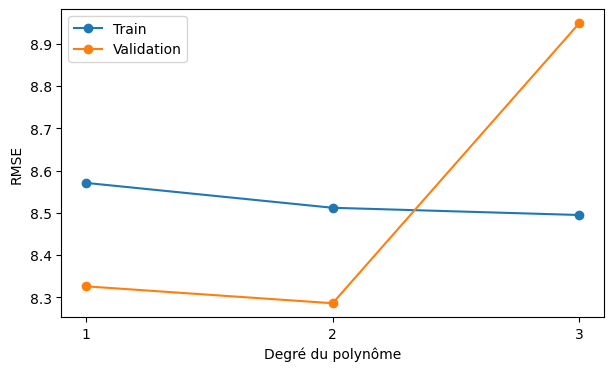

In [10]:
plt.figure(figsize=(7, 4))

plt.plot(complexity_results["degre"], complexity_results["RMSE_train"],
         marker="o", label="Train")
plt.plot(complexity_results["degre"], complexity_results["RMSE_validation"],
         marker="o", label="Validation")

plt.xlabel("Degré du polynôme")
plt.ylabel("RMSE")
plt.xticks(complexity_results["degre"])
plt.legend()
plt.show()

### Interpréter la complexité

**Q9.** Comment évolue l'erreur d'entraînement lorsque le degré augmente ?

**Q10.** L'erreur de validation évolue-t-elle nécessairement de la même manière ?

**Q11.** Quel degré choisiriez-vous à ce stade ? Justifiez uniquement à partir de l'expérience réalisée.

**Q12.** Un modèle qui obtient une erreur d'entraînement plus faible est-il nécessairement un meilleur modèle pour de nouvelles commandes ?

**Q13.** À partir de vos observations, expliquez avec vos propres mots ce que peuvent signifier **sous-apprentissage** et **sur-apprentissage**.

### ✍️ Votre réponse

**Q9.** Elle diminue. Chaque degré contient toutes les variables du degré précédent, donc le modèle peut au pire retrouver la solution précédente.

**Q10.** Non. La validation mesure l'erreur sur des données non vues, qui peut stagner ou remonter quand le modèle se complexifie. Ici, elle passe de 8.32 (degré 1) à 8.29 (degré 2) puis 8.95 (degré 3).

**Q11.** Le degré 2, car il obtient la plus faible RMSE de validation. La RMSE d'entraînement ne peut pas servir de critère puisqu'elle baisse mécaniquement avec le degré.

**Q12.** Non. Une erreur d'entraînement plus faible peut venir d'un modèle qui a appris le bruit de l'échantillon. Ce qui compte pour de nouvelles commandes, c'est l'erreur de validation.

**Q13.** Le sous-apprentissage correspond à un modèle trop simple pour capter la relation entre variables et cible. Les erreurs d'entraînement et de validation sont alors élevées toutes les deux.

Le sur-apprentissage correspond à un modèle qui colle aux particularités des données d'entraînement. L'erreur d'entraînement continue de baisser alors que l'erreur de validation stagne ou remonte.

## 7. De la complexité au compromis biais-variance

L'expérience précédente met en évidence deux risques opposés.

Un modèle trop simple dispose de peu de liberté pour représenter la relation entre les variables et la cible. À l'inverse, un modèle très flexible peut devenir fortement dépendant des particularités des données utilisées pour l'entraîner.

On parle alors de **compromis biais-variance** :

- augmenter la complexité tend à réduire le biais ;
- mais peut augmenter la variance.

La difficulté n'est donc pas de construire le modèle le plus complexe possible, mais de trouver une complexité qui permette de bien **généraliser**.

### Réflexion

**Q14.** Associez les situations suivantes à un biais plutôt élevé ou une variance plutôt élevée :

1. le modèle est trop simple pour représenter la relation présente dans les données ;
2. le modèle change fortement lorsque l'on modifie légèrement les observations d'entraînement ;
3. le modèle reproduit très bien les données d'entraînement mais se dégrade sur validation.

### ✍️ Votre réponse

**Q14.**

1. Biais élevé. Le modèle ne peut pas représenter la relation, quel que soit l'échantillon.
2. Variance élevée. Le modèle dépend trop des observations particulières du train.
3. Variance élevée. C'est le symptôme typique du sur-apprentissage.

## 8. Peut-on conserver un modèle riche tout en contrôlant sa complexité ?

Jusqu'ici, nous avons contrôlé la complexité en modifiant le degré du polynôme.

Une autre stratégie consiste à conserver une représentation riche, mais à **contraindre les coefficients** appris par le modèle.

C'est le principe de la **régularisation**.

Nous allons repartir d'une représentation polynomiale de degré 3 et utiliser une régression Ridge.

### Pourquoi standardiser ?

La régularisation agit sur la taille des coefficients.

Or nos variables n'ont pas les mêmes unités : jours, kilomètres, grammes, montant de transport, etc. Nous utilisons donc `StandardScaler` avant la régression afin de placer les variables transformées sur des échelles comparables.

## 9. Ridge : pénaliser les coefficients de grande amplitude

La régression Ridge ajoute une pénalisation de type L2.

Dans `scikit-learn`, l'intensité de cette régularisation est contrôlée par le paramètre `alpha`.

Commençons par une valeur intermédiaire.

In [11]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred_train = ridge_model.predict(X_train)
ridge_pred_val = ridge_model.predict(X_val)

print("RMSE train      :", rmse(y_train, ridge_pred_train))
print("RMSE validation :", rmse(y_val, ridge_pred_val))

RMSE train      : 8.494935899296054
RMSE validation : 8.931104042805558


### Comprendre `alpha`

**Q15.** Quel est le rôle de `alpha` dans la régression Ridge ?

**Q16.** Que vous attendez-vous à observer si `alpha` devient très grand ?

### ✍️ Votre réponse

**Q15.** `alpha` fixe le poids de la pénalité L2, la somme des carrés des coefficients, dans la fonction de coût. Plus il est grand, plus les coefficients sont tirés vers zéro. Avec `alpha = 0`, on retrouve la régression linéaire classique.

**Q16.** Les coefficients deviennent presque nuls et le modèle prédit quasiment une constante, la moyenne de la cible. Les erreurs sur train et validation augmentent toutes les deux. C'est du sous-apprentissage.

## 10. Faire varier la régularisation

Nous allons maintenant entraîner plusieurs modèles Ridge en faisant varier uniquement `alpha`.

Complétez la liste avec plusieurs valeurs couvrant des intensités de régularisation très différentes, puis calculez pour chacune la RMSE sur train et validation.

In [12]:
alphas = [
    0.001, 0.01, 0.1, 1, 10, 100,
    1_000, 10_000, 100_000, 1_000_000, 10_000_000
]

ridge_results = []

for alpha in alphas:

    model = Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)

    ridge_results.append({
        "alpha": alpha,
        "RMSE_train": rmse(y_train, pred_train),
        "RMSE_validation": rmse(y_val, pred_val)
    })

ridge_results = pd.DataFrame(ridge_results)
ridge_results

,alpha,RMSE_train,RMSE_validation
0,1.000000e-03,8.494936,8.948759
1,1.000000e-02,8.494936,8.948598
2,1.000000e-01,8.494936,8.946989
3,1.000000e+00,8.494936,8.931104
4,1.000000e+01,8.494958,8.790423
5,1.000000e+02,8.496193,8.294720
6,1.000000e+03,8.512351,8.721338
7,1.000000e+04,8.561176,8.376307
8,1.000000e+05,8.743586,8.961242
9,1.000000e+06,9.127891,8.918950


Une représentation graphique permet de mieux observer l'effet de `alpha`.

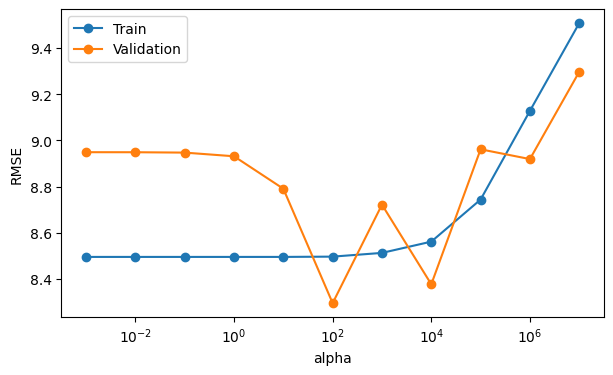

In [13]:
plt.figure(figsize=(7, 4))

plt.semilogx(ridge_results["alpha"], ridge_results["RMSE_train"],
             marker="o", label="Train")
plt.semilogx(ridge_results["alpha"], ridge_results["RMSE_validation"],
             marker="o", label="Validation")

plt.xlabel("alpha")
plt.ylabel("RMSE")
plt.legend()
plt.show()

### Analyse

**Q17.** Comment évoluent les performances sur train lorsque `alpha` augmente ?

**Q18.** Quelle valeur de `alpha` donne la meilleure RMSE de validation parmi celles testées ?

**Q19.** Que se passe-t-il lorsque la régularisation devient trop forte ?

**Q20.** Expliquez pourquoi le meilleur `alpha` ne doit pas être choisi à partir de la performance sur le jeu de test.

### ✍️ Votre réponse

**Q17.** La RMSE d'entraînement augmente avec `alpha`. Le modèle ne minimise plus seulement l'erreur sur train, il doit aussi garder des coefficients petits.

**Q18.** `alpha` = 100, avec une RMSE de validation de 8.29 jours.

**Q19.** Les coefficients sont écrasés vers zéro et le modèle ne peut plus exploiter les variables. Les RMSE train et validation augmentent ensemble et se rapprochent de l'écart-type de la cible. Le modèle sous-apprend.

**Q20.** Le test doit fournir une estimation non biaisée de la performance sur de nouvelles données. Choisir `alpha` sur le test revient à l'utiliser pour ajuster le modèle. Le score obtenu serait alors trop optimiste.

## 11. Comment Ridge agit-il sur les coefficients ?

Comparons la taille des coefficients d'un modèle polynomial sans régularisation à celle d'un modèle Ridge.

Nous utilisons la même transformation polynomiale et la même standardisation afin que la comparaison soit cohérente.

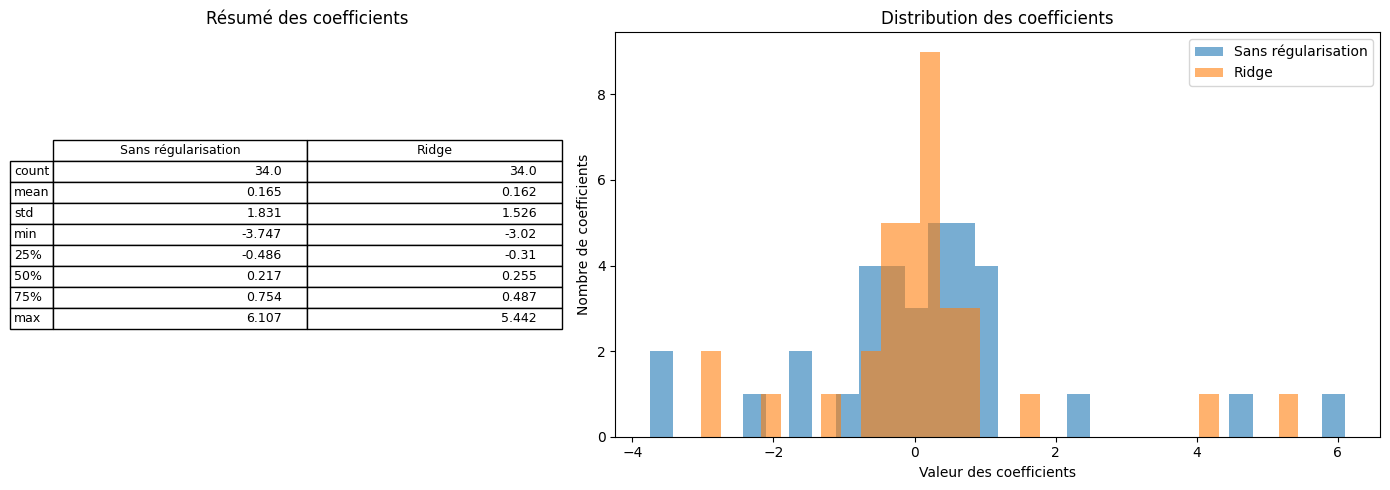

In [14]:
linear_degree_3 = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

linear_degree_3.fit(X_train, y_train)

best_alpha = ridge_results.loc[
    ridge_results["RMSE_validation"].idxmin(),
    "alpha"
]

best_ridge = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha))
])

best_ridge.fit(X_train, y_train)

coef_linear = linear_degree_3.named_steps["regression"].coef_
coef_ridge = best_ridge.named_steps["ridge"].coef_

coef_summary = pd.DataFrame({
    "Sans régularisation": coef_linear,
    "Ridge": coef_ridge
}).describe()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

axes[0].axis("off")

table = axes[0].table(
    cellText=coef_summary.round(3).values,
    rowLabels=coef_summary.index,
    colLabels=coef_summary.columns,
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.2)

axes[0].set_title("Résumé des coefficients")


axes[1].hist(
    coef_linear,
    bins=30,
    alpha=0.6,
    label="Sans régularisation"
)

axes[1].hist(
    coef_ridge,
    bins=30,
    alpha=0.6,
    label="Ridge"
)

axes[1].set_xlabel("Valeur des coefficients")
axes[1].set_ylabel("Nombre de coefficients")
axes[1].set_title("Distribution des coefficients")
axes[1].legend()

plt.tight_layout()
plt.show()

### Analyse

**Q21.** Comparez la dispersion et l'amplitude des coefficients avec et sans Ridge. Que constatez-vous ?

**Q22.** En quoi cette observation correspond-elle au principe de la régularisation étudié en cours ?

### ✍️ Votre réponse

**Q21.** Sans régularisation, les coefficients sont plus dispersés et atteignent de plus grandes valeurs, positives comme négatives. Les termes polynomiaux sont très corrélés entre eux, ce qui permet à de grands coefficients de se compenser. Avec Ridge, la distribution est resserrée autour de zéro.

**Q22.** Ridge ajoute à la perte la somme des carrés des coefficients. Les grandes valeurs deviennent coûteuses, donc le modèle les réduit. On accepte un peu plus de biais en échange de moins de variance.

## 12. Lasso : réduire ou sélectionner ?

Ridge rapproche les coefficients de zéro sans chercher à les annuler.

La régression **Lasso** utilise une pénalisation différente, appelée L1, qui peut conduire certains coefficients à devenir exactement nuls.

Nous allons vérifier expérimentalement cette propriété sur la même représentation polynomiale.

In [15]:
from sklearn.linear_model import Lasso

lasso_model = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.01, max_iter=20000))
])

lasso_model.fit(X_train, y_train)

lasso_pred_val = lasso_model.predict(X_val)
lasso_coef = lasso_model.named_steps["lasso"].coef_

print("RMSE validation :", rmse(y_val, lasso_pred_val))
print("Nombre de coefficients :", len(lasso_coef))
print("Coefficients nuls :", np.sum(np.isclose(lasso_coef, 0)))

RMSE validation : 8.31663409627621
Nombre de coefficients : 34
Coefficients nuls : 17


### Analyse

**Q23.** Certains coefficients sont-ils exactement nuls ?

**Q24.** Quelle différence observez-vous entre l'effet de Ridge et celui de Lasso sur les coefficients ?

**Q25.** Pourquoi peut-on dire que Lasso peut réaliser une forme de sélection automatique de variables ?

### ✍️ Votre réponse

**Q23.** Oui. 17 coefficients sur 34 sont exactement nuls.

**Q24.** Ridge réduit tous les coefficients sans en annuler aucun. Lasso en annule une partie et conserve les autres.

**Q25.** Un coefficient nul retire la variable correspondante de la prédiction. Lasso décide donc seul quels termes polynomiaux garder. La sélection se fait pendant l'apprentissage, sans étape séparée.

## 13. Choisir avant le test final
Nous avons maintenant réalisé plusieurs expériences :

- différents degrés polynomiaux ;
- différentes intensités de régularisation Ridge ;
- une première expérience avec Lasso.

À ce stade, le jeu de test n'a toujours pas été utilisé pour choisir le modèle.

### Décision

**Q26.** Parmi les modèles que vous avez comparés, lequel retiendriez-vous sur la base de la validation ? Justifiez à partir des résultats obtenus.

**Q27.** Quels hyperparamètres avez-vous choisis en utilisant le jeu de validation ?

**Q28.** Une fois ce choix effectué, pourquoi est-il pertinent de réentraîner le modèle sur `train + validation` avant l'évaluation finale ?

### ✍️ Votre réponse

**Q26.** Je retiens la régression Ridge sur polynôme de degré 3 avec `alpha` = 100. Meme si sa RMSE de validation (8.29) n'est pas la plus faible, elle est tres proche de celle du degre 2 (8.286), et je pense que ca reste le modele qui generalise le mieux.

**Q27.** Le degré du polynôme et l'intensité de régularisation `alpha`. Les coefficients, eux, sont appris sur train.

**Q28.** Les hyperparamètres sont fixés, la validation n'a donc plus de rôle à jouer. L'ajouter à l'entraînement donne plus de données au modèle, ce qui rend ses coefficients plus stables. Le test reste intact pour l'évaluation finale.

## 14. Évaluation finale

Une fois le modèle et ses hyperparamètres choisis, nous pouvons enfin utiliser le jeu de test.

Reprenez **le modèle que vous avez retenu**, réentraînez-le sur l'ensemble `train + validation`, puis évaluez-le une seule fois sur `test`.

Le code dépend de votre choix précédent : cette dernière étape est donc volontairement laissée à votre charge.

In [20]:
# 1. Regroupez train et validation.
train_validation = pd.concat([train, validation])

# 2. Construisez X et y avec les mêmes variables.
train_validation_poly = train_validation.dropna(subset=features).copy()
test_poly = test.dropna(subset=features).copy()

X_train_val = train_validation_poly[features]
y_train_val = train_validation_poly[target]

X_test = test_poly[features]
y_test = test_poly[target]

# 3. Reconstruisez le modèle retenu avec les hyperparamètres choisis.
final_model = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha))
])

# 4. Entraînez-le sur train + validation.
final_model.fit(X_train_val, y_train_val)

# 5. Évaluez-le sur test.
rmse_test = rmse(y_test, final_model.predict(X_test))

pd.DataFrame({
    "RMSE validation": [ridge_results["RMSE_validation"].min()],
    "RMSE test": [rmse_test]
}, index=[f"Ridge degré 3 (alpha={best_alpha})"])

,RMSE validation,RMSE test
Ridge degré 3 (alpha=100.0),8.29472,8.395155


### Dernière analyse

**Q29.** La performance sur test est-elle proche de celle observée sur validation ?

**Q30.** Si la performance test était sensiblement moins bonne que la performance validation, quelles explications pourriez-vous envisager ?

**Q31.** Pourquoi la performance d'entraînement seule aurait-elle été insuffisante pour sélectionner notre modèle ?

### ✍️ Votre réponse

**Q29.** La RMSE test vaut 8.39 jours contre 8.29 en validation. Elles sont proches, l'ecart est d'environ 0.1 jour.

**Q30.**

- Le hasard du découpage. Le test peut contenir davantage de livraisons très en retard, qui pèsent lourd dans la RMSE.
- Un sur-ajustement à la validation. À force de comparer des modèles sur le même jeu, le choix finit par en dépendre.
- Une différence de distribution entre les jeux, par exemple sur les distances ou les poids.

**Q31.** L'erreur d'entraînement baisse toujours quand la complexité augmente ou que la régularisation diminue. Elle aurait désigné le degré 3 sans régularisation, sans rien dire de sa capacité à généraliser.

## 15. Bilan

Dans ce TP, nous n'avons pas changé de problème métier : nous avons toujours cherché à prédire le délai réel de livraison.

En revanche, nous avons modifié la **complexité de la famille de modèles** utilisée pour résoudre ce problème.

Retenez la chaîne de raisonnement suivante :

**complexifier → comparer train et validation → observer la généralisation → régulariser → choisir sur validation → évaluer une seule fois sur test**